Proiect TDAV Jakab Claudia Angela, Ungur Andreea Cristina - Crowd density estimation

Încărcare Video, configurare și analizare  (Warm-up)

Modelul învăță elementele statice din scenă.

Antrenare model fundal in curs...
Model fundal stabilit. Cadru test extras.


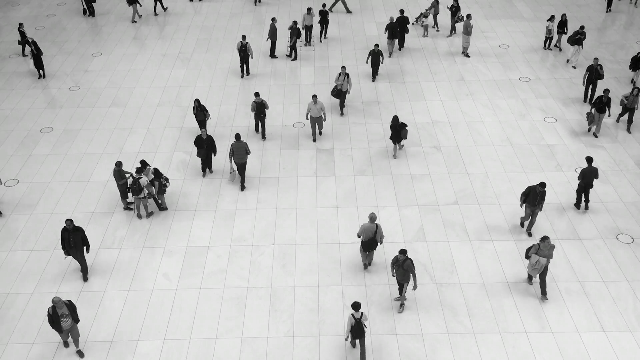

In [12]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

# 1. Configurare sursă video
video_path = 'video1.mp4'
cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    print("Eroare: Fisierul video nu a fost gasit!")
else:
    # 2. Inițializare MOG2: Se creează obiectul de substracție a fundalului
    fgbg = cv2.createBackgroundSubtractorMOG2(history=500, varThreshold=25, detectShadows=True)

    print("Antrenare model fundal in curs...")

    # 3. Warm-up (Cadrele 1-60): Algoritmul analizează primele cadre pentru a învăța ce este static
    for i in range(60):
        ret, frame_train = cap.read()
        if not ret:
            break

        # Filtrare (Grayscale + Blur): Se aplică pentru a învăța un fundal "curat", fără zgomot
        gray_train = cv2.cvtColor(frame_train, cv2.COLOR_BGR2GRAY)
        blurred_train = cv2.GaussianBlur(gray_train, (5, 5), 0)

        # Actualizare memorie statistică fundal
        fgbg.apply(blurred_train)

    # 4. Extragere cadru pentru demonstrație
    ret, frame_test = cap.read()

    if ret:
        print("Model fundal stabilit. Cadru test extras.")
        cv2_imshow(cv2.resize(frame_test, (640, 360)))
    else:
        print("Eroare la extragerea cadrului de test.")

Preprocesare (Filtrare)

Pregătirea cadrului curent pentru comparația cu fundalul.

Imaginea a fost filtrată (Blur)


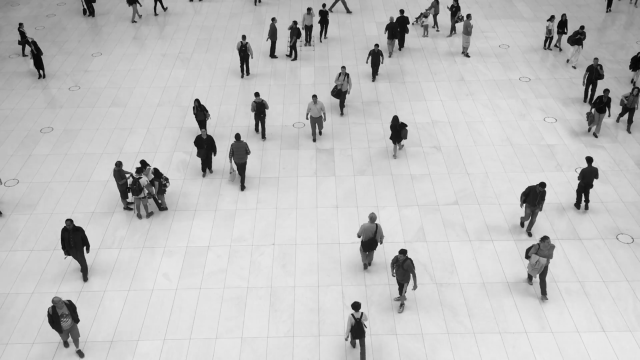

In [13]:
# Conversie Grayscale: Reduce complexitatea datelor de la 3 canale color la unul singur.
gray = cv2.cvtColor(frame_test, cv2.COLOR_BGR2GRAY)

# Filtrare Gaussiană pentru eliminarea zgomotului digital
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

print("Imaginea a fost filtrată (Blur)")
cv2_imshow(cv2.resize(blurred, (640, 360)))

MOG2 (Segmentarea Pixel-wise)

Algoritmul compară pixelul curent cu modelul de fundal. Dacă diferența este mare, pixelul devine alb.

$$|I(x, y) - B(x, y)| > \tau$$

Mască binară (Rezultat segmentare)


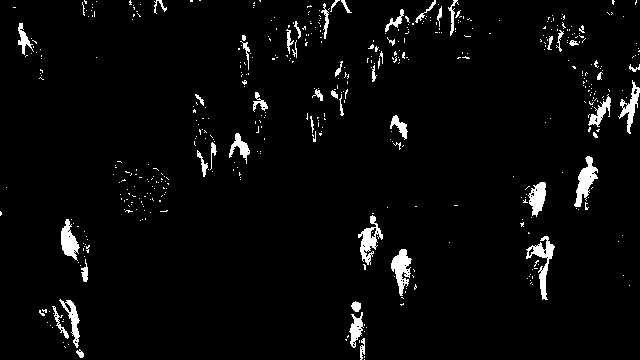

In [14]:
# 1. Calcul mască mișcare (LearningRate mic păstrează obiectele persistente în scenă)
fgmask = fgbg.apply(blurred, learningRate=0.01)

# 2. Binarizare mască (Prag scăzut pentru a include umbrele și detaliile slabe)
_, stage2_mask = cv2.threshold(fgmask, 127, 255, cv2.THRESH_BINARY)

print("Mască binară (Rezultat segmentare)")

# Validare detecție și afișare rezultat (Diagnostic în caz de mască goală)
if np.count_nonzero(stage2_mask) == 0:
    print("AVERTISMENT: Mască goală. Se afișează masca brută (fgmask) pentru diagnoză:")
    cv2_imshow(cv2.resize(fgmask, (640, 360)))
else:
    cv2_imshow(cv2.resize(stage2_mask, (640, 360)))

Rafinare Morfologică

Corectăm erorile măștii. „Închidem” găurile din interiorul oamenilor și „deschidem” imaginea pentru a șterge punctele mici (zgomotul).



Masca rafinată prin operații morfologice


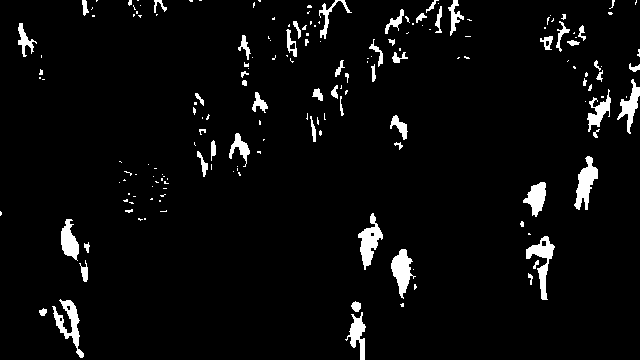

In [15]:
kernel = np.ones((3,3), np.uint8)
# Closing: unifică fragmentele aceleiași persoane
mask_closed = cv2.morphologyEx(stage2_mask, cv2.MORPH_CLOSE, kernel, iterations=3)
# Opening: elimină zgomotul rezidual
stage3_refined = cv2.morphologyEx(mask_closed, cv2.MORPH_OPEN, kernel, iterations=1)

print("Masca rafinată prin operații morfologice")
cv2_imshow(cv2.resize(stage3_refined, (640, 360)))

Watershed & Distance Transform

 Aceasta este etapa de separare. Distance Transform găsește „centrul” fiecărei persoane, creând markerii necesari pentru Watershed.

Nucleele identificate pentru separarea persoanelor lipite


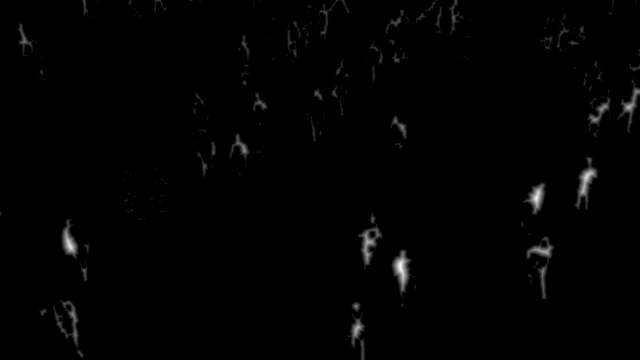

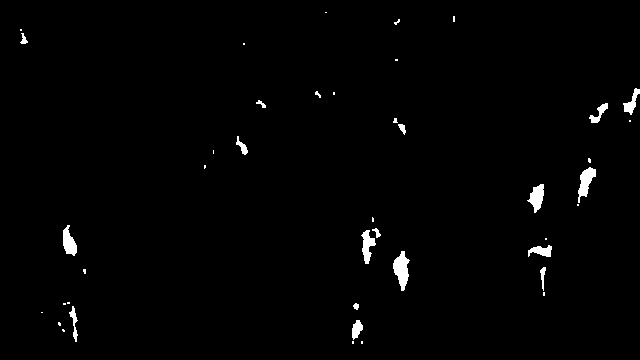

In [16]:
# Calculăm distanța față de cel mai apropiat pixel negru
dist_transform = cv2.distanceTransform(stage3_refined, cv2.DIST_L2, 5)

# Aplicăm un Blur pe harta de distanțe pentru a uni vârfurile locale
dist_smoothed = cv2.GaussianBlur(dist_transform, (15, 15), 0)

# Normalizăm pentru vizualizare
dist_visual = cv2.normalize(dist_transform, None, 0, 255, cv2.NORM_MINMAX)
dist_visual = np.uint8(dist_visual)

# Identificăm nucleele (markerii)
_, stage4_markers = cv2.threshold(dist_transform, 0.3 * dist_transform.max(), 255, 0)
stage4_markers = np.uint8(stage4_markers)

# Adăugăm o mică dilatare a markerilor pentru a uni punctele foarte apropiate
stage4_markers = cv2.dilate(stage4_markers, kernel, iterations=2)

print("Nucleele identificate pentru separarea persoanelor lipite")
cv2_imshow(cv2.resize(dist_visual, (640, 360))) # Arătăm harta de distanțe
cv2_imshow(cv2.resize(stage4_markers, (640, 360))) # Arătăm markerii de separare

Analiza Blobs & Densitate

Curățăm imaginea și lipim fragmentele de corp într-un singur obiect unitar. Obținem numărul real de persoane și calculăm procentul exact de ocupare a spațiului.

Persoane detectate: 45
Densitate: 4.37%


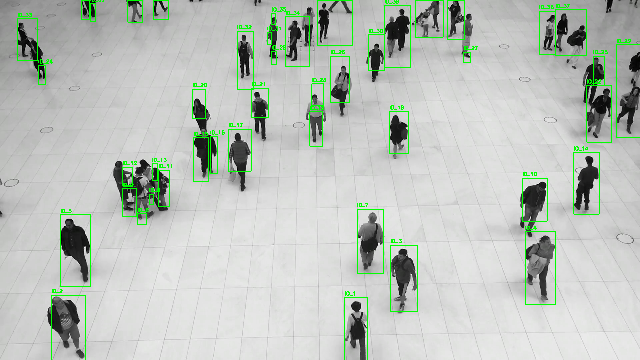

In [17]:
# 1. Calculăm procentul de aglomerare (cât din podea este acoperită de oameni)
white_pixels = np.count_nonzero(stage3_refined)
total_pixels = stage3_refined.size
density_percentage = (white_pixels / total_pixels) * 100

# 2. Aplicăm o dilatare verticală pentru a unifica segmentele corpului (cap-corp-picioare)
kernel_fusion = np.ones((25, 5), np.uint8)
mask_fused = cv2.dilate(stage3_refined, kernel_fusion, iterations=1)

# 3. Identificăm contururile și filtrăm doar formele înalte, specifice siluetei umane
contours, _ = cv2.findContours(mask_fused, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
rects = []

for cnt in contours:
    x, y, w, h = cv2.boundingRect(cnt)
    area = cv2.contourArea(cnt)

    # Filtrăm obiectele prea mici sau cele orizontale care sigur nu sunt oameni
    if area > 300 and h > w:
        # Înregistrăm cutia de două ori; este o cerință tehnică pentru a valida gruparea de mai jos
        rects.append([x, y, w, h])
        rects.append([x, y, w, h])

# 4. Unim dreptunghiurile care se suprapun pe același om pentru a nu-l număra de mai multe ori
rects, weights = cv2.groupRectangles(rects, groupThreshold=1, eps=0.5)

# 5. Desenăm rezultatul curat peste imaginea originală
frame_final = frame_test.copy()
count_final = 0

for (x, y, w, h) in rects:
    count_final += 1
    cv2.rectangle(frame_final, (x, y), (x + w, y + h), (0, 255, 0), 2)
    cv2.putText(frame_final, f"ID_{count_final}", (x, y-7),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)

# Afișăm statisticile finale

print(f"Persoane detectate: {count_final}")
print(f"Densitate: {density_percentage:.2f}%")

cv2_imshow(cv2.resize(frame_final, (640, 360)))

Export Video Final

In [18]:
# Resetăm videoclipul pentru a începe procesarea de la primul cadru
cap = cv2.VideoCapture(video_path)

# 1. Configurare salvare (Codecuri și dimensiuni)
width  = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps    = int(cap.get(cv2.CAP_PROP_FPS))
output_file = 'rezultat_detectie_persoane.mp4'

fourcc = cv2.VideoWriter_fourcc(*'MP4V')
out = cv2.VideoWriter(output_file, fourcc, fps, (width, height))

# Pregătim uneltele de procesare
kernel_small = np.ones((3,3), np.uint8)
kernel_fusion = np.ones((25, 5), np.uint8) # Pensula verticală pentru unificarea siluetelor

print(f"Procesare în curs... Rezultatul va fi salvat în: {output_file}")

while True:
    ret, frame = cap.read()
    if not ret: break

    # ETAPA 1 & 2: Pregătire
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    fgmask = fgbg.apply(blurred, learningRate=0.01)
    _, mask = cv2.threshold(fgmask, 127, 255, cv2.THRESH_BINARY)

    # ETAPA 3: Rafinare Morfologică
    mask_closed = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel_small, iterations=3)
    mask_refined = cv2.morphologyEx(mask_closed, cv2.MORPH_OPEN, kernel_small, iterations=1)

    # ETAPA 5: Analiza Blobs & Densitate
    # Calculăm densitatea pentru cadrul curent
    white_pixels = np.count_nonzero(mask_refined)
    density = (white_pixels / mask_refined.size) * 100

    # Unificăm segmentele corpului pe verticală
    mask_fused = cv2.dilate(mask_refined, kernel_fusion, iterations=1)

    contours, _ = cv2.findContours(mask_fused, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    rects = []

    for cnt in contours:
        x, y, w, h = cv2.boundingRect(cnt)
        area = cv2.contourArea(cnt)

        # Filtrăm doar obiectele "în picioare" și suficient de mari (aria > 300)
        if area > 300 and h > w:
            # Înregistrăm cutia de două ori pentru algoritmul de grupare
            rects.append([x, y, w, h])
            rects.append([x, y, w, h])

    # Unim dreptunghiurile care se suprapun (NMS / Grouping)
    rects, _ = cv2.groupRectangles(rects, groupThreshold=1, eps=0.5)

    # --- DESENARE ȘI EXPORT ---
    for i, (x, y, w, h) in enumerate(rects):
        # Desenăm dreptunghiul de detecție
        cv2.rectangle(frame, (x, y), (x + w, y + h), (0, 255, 0), 2)
        # Adăugăm ID-ul persoanei
        cv2.putText(frame, f"ID_{i+1}", (x, y-7), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)

    # Adăugăm statisticile globale pe video
    cv2.putText(frame, f"Persoane: {len(rects)}", (30, 50), 1, 2, (0, 0, 255), 3)
    cv2.putText(frame, f"Densitate: {density:.2f}%", (30, 90), 1, 1.5, (255, 0, 0), 2)

    # Scriem cadrul în noul fișier video
    out.write(frame)

# Finalizare
cap.release()
out.release()
print(f"Gata! Videoclipul final a fost exportat cu succes.")

Procesare în curs... Rezultatul va fi salvat în: rezultat_detectie_persoane.mp4
Gata! Videoclipul final a fost exportat cu succes.
